In [20]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import os
import glob
import time
import random
from pathlib import Path
from collections import defaultdict, OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.11.0+cpu
CUDA available: False


In [ ]:
# Define paths for the full xBD train folder on your Windows laptop
# This version uses the FULL dataset, resizes images/masks to 512 x 512,
# and keeps train/validation/test loaders for early-stopping experiments.
from pathlib import Path
from collections import defaultdict
train_path = Path.home() / "Downloads" / "xbd" / "train"
images_path = train_path / "images"
targets_path = train_path / "targets"   # target mask images
labels_path = train_path / "labels"     # JSON labels, not used directly here

# ----------------------------
# Full dataset settings
# ----------------------------
USE_FULL_DATASET = True
IMAGE_SIZE = (512, 512)
RANDOM_SEED = 42
BATCH_SIZE = 4  # 512x512 is memory-heavy. Increase to 2/4 only if your GPU/RAM survives.
NUM_WORKERS = 0 # Keep 0 on Windows/Jupyter to avoid DataLoader issues.

# Optional safety switch. Keep None to use the full dataset.
# Example: set MAX_TOTAL_PAIRS = 1000 for a quick debugging run.
MAX_TOTAL_PAIRS = 2799

# ----------------------------
# Helper functions
# ----------------------------
def get_event_id(path):
    """Return the common event id, e.g. hurricane-michael_00000001."""
    name = path.name
    for suffix in [
        "_pre_disaster_target.png",
        "_post_disaster_target.png",
        "_pre_disaster.png",
        "_post_disaster.png",
    ]:
        name = name.replace(suffix, "")
    return name

def get_disaster_name(path_or_event_id):
    """Return disaster name before the numeric id."""
    text = path_or_event_id.name if hasattr(path_or_event_id, "name") else str(path_or_event_id)
    return text.split("_")[0]

def build_matched_pairs(images_path, targets_path):
    """Match pre image, post image, pre mask, post mask using event id."""
    pre_imgs = {get_event_id(p): p for p in images_path.glob("*_pre_disaster.png")}
    post_imgs = {get_event_id(p): p for p in images_path.glob("*_post_disaster.png")}
    pre_masks = {get_event_id(p): p for p in targets_path.glob("*_pre_disaster_target.png")}
    post_masks = {get_event_id(p): p for p in targets_path.glob("*_post_disaster_target.png")}

    common_ids = sorted(set(pre_imgs) & set(post_imgs) & set(pre_masks) & set(post_masks))

    pairs = []
    for event_id in common_ids:
        pairs.append({
            "event_id": event_id,
            "disaster": get_disaster_name(event_id),
            "pre_img": pre_imgs[event_id],
            "post_img": post_imgs[event_id],
            "pre_mask": pre_masks[event_id],
            "post_mask": post_masks[event_id],
        })
    return pairs

# ----------------------------
# Load full dataset
# ----------------------------
assert images_path.exists(), f"Images folder not found: {images_path}"
assert targets_path.exists(), f"Targets folder not found: {targets_path}"

all_pairs = build_matched_pairs(images_path, targets_path)
assert len(all_pairs) > 0, "No matched image/mask pairs found. Check folder names and target mask filenames."

available_disasters = sorted(set(p["disaster"] for p in all_pairs))
print("Available disasters:", available_disasters)
print("Total matched pairs in full dataset:", len(all_pairs))

random.seed(RANDOM_SEED)
filtered_pairs = all_pairs.copy()
random.shuffle(filtered_pairs)

if MAX_TOTAL_PAIRS is not None:
    filtered_pairs = filtered_pairs[:MAX_TOTAL_PAIRS]
    print(f"DEBUG MODE: using only {len(filtered_pairs)} total pairs")
else:
    print("Using the full matched dataset.")

# Count pairs per disaster so you can report the dataset distribution.
pairs_by_disaster = defaultdict(int)
for pair in filtered_pairs:
    pairs_by_disaster[pair["disaster"]] += 1

print("Pairs per disaster used:")
for disaster, count in sorted(pairs_by_disaster.items()):
    print(f"  {disaster}: {count}")

# ----------------------------
# Train / validation / test split
# ----------------------------
n = len(filtered_pairs)
train_end = int(0.70 * n)
val_end = int(0.85 * n)

train_pairs = filtered_pairs[:train_end]
val_pairs = filtered_pairs[train_end:val_end]
test_pairs = filtered_pairs[val_end:]

print(f"Train pairs: {len(train_pairs)}")
print(f"Validation pairs: {len(val_pairs)}")
print(f"Test pairs: {len(test_pairs)}")

# ----------------------------
# Custom Dataset
# ----------------------------
class CustomDataset(Dataset):
    def __init__(self, pairs, image_size=(512, 512), num_seg_classes=2, num_damage_classes=5):
        self.pairs = pairs
        self.image_size = image_size
        self.num_seg_classes = num_seg_classes
        self.num_damage_classes = num_damage_classes

    def __len__(self):
        return len(self.pairs)

    def _load_image(self, path):
        img = Image.open(path).convert("RGB")
        img = TF.resize(img, self.image_size, interpolation=InterpolationMode.BILINEAR)
        img = TF.to_tensor(img)  # float tensor in [0, 1], shape: 3 x H x W
        return img

    def _load_mask_one_hot(self, path, num_classes):
        # Masks must use NEAREST interpolation to avoid inventing fake class values.
        mask = Image.open(path).convert("L")
        mask = TF.resize(mask, self.image_size, interpolation=InterpolationMode.NEAREST)
        mask = torch.as_tensor(np.array(mask), dtype=torch.long)

        # Safety clamp in case mask contains unexpected values.
        mask = torch.clamp(mask, min=0, max=num_classes - 1)

        # Return one-hot because the current training loop uses torch.argmax(mask, dim=1).
        mask = F.one_hot(mask, num_classes=num_classes).permute(2, 0, 1).float()
        return mask

    def __getitem__(self, idx):
        pair = self.pairs[idx]

        preImg = self._load_image(pair["pre_img"])
        postImg = self._load_image(pair["post_img"])

        # Pre-disaster target is building localization: background/building.
        preMask = self._load_mask_one_hot(pair["pre_mask"], num_classes=self.num_seg_classes)

        # Post-disaster target is damage classification: background + damage classes.
        postMask = self._load_mask_one_hot(pair["post_mask"], num_classes=self.num_damage_classes)

        return preImg, preMask, postImg, postMask

# ----------------------------
# DataLoaders
# ----------------------------
train_dataset = CustomDataset(train_pairs, image_size=IMAGE_SIZE)
val_dataset = CustomDataset(val_pairs, image_size=IMAGE_SIZE)
test_dataset = CustomDataset(test_pairs, image_size=IMAGE_SIZE)

# Keep this name so your existing training loop still works.
data_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)

val_data_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_data_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(data_loader))
print("Validation batches:", len(val_data_loader))
print("Test batches:", len(test_data_loader))


Available disasters: ['guatemala-volcano', 'hurricane-florence', 'hurricane-harvey', 'hurricane-matthew', 'hurricane-michael', 'mexico-earthquake', 'midwest-flooding', 'palu-tsunami', 'santa-rosa-wildfire', 'socal-fire']
Total matched pairs in full dataset: 2799
DEBUG MODE: using only 2799 total pairs
Pairs per disaster used:
  guatemala-volcano: 18
  hurricane-florence: 319
  hurricane-harvey: 319
  hurricane-matthew: 238
  hurricane-michael: 343
  mexico-earthquake: 121
  midwest-flooding: 279
  palu-tsunami: 113
  santa-rosa-wildfire: 226
  socal-fire: 823
Train pairs: 1959
Validation pairs: 420
Test pairs: 420
Image size: (512, 512)
Batch size: 4
Training batches: 490
Validation batches: 105
Test batches: 105


In [4]:
# Display image and label.
pre_features, pre_labels, post_features, post_labels,  = next(iter(data_loader))
print(f"Feature batch shape: {pre_features.size()}")
print(f"Labels batch shape: {pre_labels.size()}")
print(f"Feature batch shape: {post_features.size()}")
print(f"Labels batch shape: {post_labels.size()}")
# img = train_features[0].squeeze()

Feature batch shape: torch.Size([4, 3, 512, 512])
Labels batch shape: torch.Size([4, 2, 512, 512])
Feature batch shape: torch.Size([4, 3, 512, 512])
Labels batch shape: torch.Size([4, 5, 512, 512])


In [5]:
data_loader.__len__()

35

In [6]:
class SiamUnet(nn.Module):

    def __init__(self, in_channels=3, out_channels_s=2, out_channels_c=5, init_features=16):
        super(SiamUnet, self).__init__()

        features = init_features

        # UNet layers
        self.encoder1 = SiamUnet._block(in_channels, features, name="enc1")
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.encoder2 = SiamUnet._block(features, features * 2, name="enc2")
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.encoder3 = SiamUnet._block(features * 2, features * 4, name="enc3")
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.encoder4 = SiamUnet._block(features * 4, features * 8, name="enc4")
        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.bottleneck = SiamUnet._block(features * 8, features * 16, name="bottleneck")

        self.upconv4 = nn.ConvTranspose2d(features * 16, features * 8, kernel_size=2, stride=2)
        self.decoder4 = SiamUnet._block((features * 8) * 2, features * 8, name="dec4")
        self.upconv3 = nn.ConvTranspose2d(features * 8, features * 4, kernel_size=2, stride=2)
        self.decoder3 = SiamUnet._block((features * 4) * 2, features * 4, name="dec3")
        self.upconv2 = nn.ConvTranspose2d(features * 4, features * 2, kernel_size=2, stride=2)
        self.decoder2 = SiamUnet._block((features * 2) * 2, features * 2, name="dec2")
        self.upconv1 = nn.ConvTranspose2d(features * 2, features, kernel_size=2, stride=2)
        self.decoder1 = SiamUnet._block(features * 2, features, name="dec1")

        self.conv_s = nn.Conv2d(in_channels=features, out_channels=out_channels_s, kernel_size=1)

        # Siamese classifier layers
        self.upconv4_c = nn.ConvTranspose2d(features * 16, features * 8, kernel_size=2, stride=2)
        self.conv4_c = SiamUnet._block(features * 16, features * 16, name="conv4")

        self.upconv3_c = nn.ConvTranspose2d(features * 16, features * 4, kernel_size=2, stride=2)
        self.conv3_c = SiamUnet._block(features * 8, features * 8, name="conv3")

        self.upconv2_c = nn.ConvTranspose2d(features * 8, features * 2, kernel_size=2, stride=2)
        self.conv2_c = SiamUnet._block(features * 4, features * 4, name="conv2")

        self.upconv1_c = nn.ConvTranspose2d(features * 4, features, kernel_size=2, stride=2)
        self.conv1_c = SiamUnet._block(features * 2, features * 2, name="conv1")

        self.conv_c = nn.Conv2d(in_channels=features * 2, out_channels=out_channels_c, kernel_size=1)


    def forward(self, x1, x2):

        # UNet on x1
        enc1_1 = self.encoder1(x1)
        enc2_1 = self.encoder2(self.pool1(enc1_1))
        enc3_1 = self.encoder3(self.pool2(enc2_1))
        enc4_1 = self.encoder4(self.pool3(enc3_1))

        bottleneck_1 = self.bottleneck(self.pool4(enc4_1))

        dec4_1 = self.upconv4(bottleneck_1)
        dec4_1 = torch.cat((dec4_1, enc4_1), dim=1)
        dec4_1 = self.decoder4(dec4_1)
        dec3_1 = self.upconv3(dec4_1)
        dec3_1 = torch.cat((dec3_1, enc3_1), dim=1)
        dec3_1 = self.decoder3(dec3_1)
        dec2_1 = self.upconv2(dec3_1)
        dec2_1 = torch.cat((dec2_1, enc2_1), dim=1)
        dec2_1 = self.decoder2(dec2_1)
        dec1_1 = self.upconv1(dec2_1)
        dec1_1 = torch.cat((dec1_1, enc1_1), dim=1)
        dec1_1 = self.decoder1(dec1_1)

        # UNet on x2
        enc1_2 = self.encoder1(x2)
        enc2_2 = self.encoder2(self.pool1(enc1_2))
        enc3_2 = self.encoder3(self.pool2(enc2_2))
        enc4_2 = self.encoder4(self.pool3(enc3_2))

        bottleneck_2 = self.bottleneck(self.pool4(enc4_2))

        dec4_2 = self.upconv4(bottleneck_2)
        dec4_2 = torch.cat((dec4_2, enc4_2), dim=1)
        dec4_2 = self.decoder4(dec4_2)
        dec3_2 = self.upconv3(dec4_2)
        dec3_2 = torch.cat((dec3_2, enc3_2), dim=1)
        dec3_2 = self.decoder3(dec3_2)
        dec2_2 = self.upconv2(dec3_2)
        dec2_2 = torch.cat((dec2_2, enc2_2), dim=1)
        dec2_2 = self.decoder2(dec2_2)
        dec1_2 = self.upconv1(dec2_2)
        dec1_2 = torch.cat((dec1_2, enc1_2), dim=1)
        dec1_2 = self.decoder1(dec1_2)

        # Siamese
        dec1_c = bottleneck_2 - bottleneck_1

        dec1_c = self.upconv4_c(dec1_c) # features * 16 -> features * 8
        diff_2 = enc4_2 - enc4_1 # features * 16 -> features * 8
        dec2_c = torch.cat((diff_2, dec1_c), dim=1) #512
        dec2_c = self.conv4_c(dec2_c)

        dec2_c = self.upconv3_c(dec2_c) # 512->256
        diff_3 = enc3_2 - enc3_1
        dec3_c = torch.cat((diff_3, dec2_c), dim=1) # ->512
        dec3_c = self.conv3_c(dec3_c)

        dec3_c = self.upconv2_c(dec3_c) #512->256
        diff_4 = enc2_2 - enc2_1
        dec4_c = torch.cat((diff_4, dec3_c), dim=1) #
        dec4_c = self.conv2_c(dec4_c)

        dec4_c = self.upconv1_c(dec4_c)
        diff_5 = enc1_2 - enc1_1
        dec5_c = torch.cat((diff_5, dec4_c), dim=1)
        dec5_c = self.conv1_c(dec5_c)

        return self.conv_s(dec1_1), self.conv_s(dec1_2), self.conv_c(dec5_c)

    @staticmethod
    def _block(in_channels, features, name):
        return nn.Sequential(
            OrderedDict(
                [
                    (
                        name + "conv1",
                        nn.Conv2d(
                            in_channels=in_channels,
                            out_channels=features,
                            kernel_size=3,
                            padding=1,
                            bias=False,
                        ),
                    ),
                    (name + "norm1", nn.BatchNorm2d(num_features=features)),
                    (name + "relu1", nn.ReLU(inplace=True)),
                    (
                        name + "conv2",
                        nn.Conv2d(
                            in_channels=features,
                            out_channels=features,
                            kernel_size=3,
                            padding=1,
                            bias=False,
                        ),
                    ),
                    (name + "norm2", nn.BatchNorm2d(num_features=features)),
                    (name + "relu2", nn.ReLU(inplace=True)),
                ]
            )
        )

In [7]:
from collections import OrderedDict

In [8]:
import time

# Training, evaluation, and required outputs

This section trains the Siamese U-Net, saves the best checkpoint using validation accuracy, prints quantitative metrics, and creates qualitative result figures.

In [9]:
# ----------------------------
# Device, paths, and reproducibility
# ----------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

MODEL_DIR = Path.home() / "Downloads" / "xbd" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = MODEL_DIR / "siamUnet_best_val_acc_state_dict.pt"
LAST_MODEL_PATH = MODEL_DIR / "siamUnet_last_state_dict.pt"
RESULTS_DIR = Path.home() / "Downloads" / "xbd" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Best model path:", BEST_MODEL_PATH)
print("Results folder:", RESULTS_DIR)

CLASS_NAMES = ["background", "no_damage", "minor_damage", "major_damage", "destroyed"]
NUM_DAMAGE_CLASSES = len(CLASS_NAMES)

Using device: cpu
Best model path: C:\Users\Jana Ehab\Downloads\xbd\models\siamUnet_best_val_acc_state_dict.pt
Results folder: C:\Users\Jana Ehab\Downloads\xbd\results


In [10]:
# ----------------------------
# Metric helpers
# ----------------------------
def confusion_matrix_from_logits(logits, targets, num_classes):
    """Return a num_classes x num_classes confusion matrix for segmentation logits."""
    preds = torch.argmax(logits, dim=1).detach().view(-1).cpu()
    targets = targets.detach().view(-1).cpu()

    valid = (targets >= 0) & (targets < num_classes)
    targets = targets[valid]
    preds = preds[valid]

    indices = num_classes * targets + preds
    cm = torch.bincount(indices, minlength=num_classes ** 2).reshape(num_classes, num_classes)
    return cm


def metrics_from_confusion_matrix(cm, class_names=None):
    """Compute pixel accuracy, per-class precision/recall/F1/IoU/Dice, and macro averages."""
    cm = cm.to(torch.float64)
    tp = torch.diag(cm)
    support = cm.sum(dim=1)
    predicted = cm.sum(dim=0)
    total = cm.sum().clamp(min=1)

    pixel_accuracy = tp.sum() / total
    precision = tp / predicted.clamp(min=1)
    recall = tp / support.clamp(min=1)
    f1 = 2 * precision * recall / (precision + recall).clamp(min=1e-12)
    iou = tp / (support + predicted - tp).clamp(min=1)
    dice = 2 * tp / (support + predicted).clamp(min=1)

    # Only include classes that appear in the ground truth when computing macro averages.
    valid_classes = support > 0
    if valid_classes.any():
        macro_precision = precision[valid_classes].mean()
        macro_recall = recall[valid_classes].mean()
        macro_f1 = f1[valid_classes].mean()
        mean_iou = iou[valid_classes].mean()
        mean_dice = dice[valid_classes].mean()
    else:
        macro_precision = macro_recall = macro_f1 = mean_iou = mean_dice = torch.tensor(0.0)

    summary = {
        "pixel_accuracy": float(pixel_accuracy),
        "macro_precision": float(macro_precision),
        "macro_recall": float(macro_recall),
        "macro_f1": float(macro_f1),
        "mean_iou": float(mean_iou),
        "mean_dice": float(mean_dice),
    }

    rows = []
    for i in range(cm.shape[0]):
        rows.append({
            "class_id": i,
            "class_name": class_names[i] if class_names and i < len(class_names) else str(i),
            "support_pixels": int(support[i].item()),
            "precision": float(precision[i]),
            "recall": float(recall[i]),
            "f1": float(f1[i]),
            "iou": float(iou[i]),
            "dice": float(dice[i]),
        })

    return summary, pd.DataFrame(rows)


def print_metrics_table(title, summary, per_class_df):
    print("\n" + "=" * 80)
    print(title)
    print("=" * 80)
    summary_df = pd.DataFrame([summary])
    display(summary_df)
    print("\nPer-class metrics:")
    display(per_class_df)
    return summary_df

In [11]:
# ----------------------------
# Loss functions
# ----------------------------
def dice_loss_from_logits(logits, targets, num_classes, smooth=1e-6):
    """Multi-class Dice loss for segmentation. Targets shape: [B, H, W]."""
    probs = torch.softmax(logits, dim=1)
    targets_one_hot = F.one_hot(targets, num_classes=num_classes).permute(0, 3, 1, 2).float()

    dims = (0, 2, 3)
    intersection = torch.sum(probs * targets_one_hot, dims)
    union = torch.sum(probs + targets_one_hot, dims)
    dice = (2.0 * intersection + smooth) / (union + smooth)
    return 1.0 - dice.mean()


class CrossEntropyDiceLoss(nn.Module):
    def __init__(self, num_classes, ce_weight=None, dice_weight=1.0):
        super().__init__()
        self.num_classes = num_classes
        self.ce = nn.CrossEntropyLoss(weight=ce_weight)
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        return self.ce(logits, targets) + self.dice_weight * dice_loss_from_logits(logits, targets, self.num_classes)


# Main experiment settings. Change these for your optimizer/loss experiments.
LOSS_NAME = "cross_entropy"       # options: "cross_entropy", "ce_dice"
OPTIMIZER_NAME = "adam"           # options: "adam", "adamw", "sgd"
LEARNING_RATE = 1e-3

criterion_seg = nn.CrossEntropyLoss()
if LOSS_NAME == "cross_entropy":
    criterion_damage = nn.CrossEntropyLoss()
elif LOSS_NAME == "ce_dice":
    criterion_damage = CrossEntropyDiceLoss(num_classes=NUM_DAMAGE_CLASSES)
else:
    raise ValueError(f"Unknown LOSS_NAME: {LOSS_NAME}")

print("Damage loss:", LOSS_NAME)

Damage loss: cross_entropy


In [12]:
# ----------------------------
# Evaluation function
# ----------------------------
def evaluate_model(model, loader, criterion_seg, criterion_damage, device, max_batches=None):
    model.eval()
    total_loss = 0.0
    batches = 0
    damage_cm = torch.zeros((NUM_DAMAGE_CLASSES, NUM_DAMAGE_CLASSES), dtype=torch.long)

    with torch.no_grad():
        for batch_idx, (pre_img, pre_mask, post_img, post_mask) in enumerate(loader):
            if max_batches is not None and batch_idx >= max_batches:
                break

            pre_img = pre_img.to(device)
            post_img = post_img.to(device)

            # pre mask: [B, 2, H, W] -> [B, H, W]
            pre_target = torch.argmax(pre_mask, dim=1).long().to(device)

            # post mask: [B, 5, H, W] -> [B, H, W]
            post_damage_target = torch.argmax(post_mask, dim=1).long().to(device)

            # binary post-building segmentation target for outputs[1]
            post_seg_target = (post_damage_target > 0).long()

            seg_pre_logits, seg_post_logits, damage_logits = model(pre_img, post_img)

            loss1 = criterion_seg(seg_pre_logits, pre_target)
            loss2 = criterion_seg(seg_post_logits, post_seg_target)
            loss3 = criterion_damage(damage_logits, post_damage_target)
            loss = loss1 + loss2 + loss3

            total_loss += loss.item()
            batches += 1
            damage_cm += confusion_matrix_from_logits(damage_logits, post_damage_target, NUM_DAMAGE_CLASSES)

    avg_loss = total_loss / max(batches, 1)
    summary, per_class_df = metrics_from_confusion_matrix(damage_cm, CLASS_NAMES)
    summary["loss"] = avg_loss
    return summary, per_class_df, damage_cm

In [14]:
# ----------------------------
# Training loop with early stopping on validation pixel accuracy
# ----------------------------
model = SiamUnet().to(DEVICE)

if OPTIMIZER_NAME == "adam":
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
elif OPTIMIZER_NAME == "adamw":
    optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
elif OPTIMIZER_NAME == "sgd":
    optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=0.9)
else:
    raise ValueError(f"Unknown OPTIMIZER_NAME: {OPTIMIZER_NAME}")

num_epochs = 6
patience = 5
min_delta = 1e-4
EARLY_STOP_VAL_ACC = None  # example: 0.90 to stop once validation pixel accuracy reaches 90%

best_val_acc = 0.0
epochs_without_improvement = 0
history = []

print(f"Training SiamUnet | loss={LOSS_NAME} | optimizer={OPTIMIZER_NAME} | lr={LEARNING_RATE}")

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    start_time = time.time()

    print(f"\nStart of epoch {epoch + 1}/{num_epochs}")

    for step, (pre_img, pre_mask, post_img, post_mask) in enumerate(data_loader, start=1):
        pre_img = pre_img.to(DEVICE)
        post_img = post_img.to(DEVICE)

        pre_target = torch.argmax(pre_mask, dim=1).long().to(DEVICE)
        post_damage_target = torch.argmax(post_mask, dim=1).long().to(DEVICE)
        post_seg_target = (post_damage_target > 0).long()

        optimizer.zero_grad()
        seg_pre_logits, seg_post_logits, damage_logits = model(pre_img, post_img)

        loss1 = criterion_seg(seg_pre_logits, pre_target)
        loss2 = criterion_seg(seg_post_logits, post_seg_target)
        loss3 = criterion_damage(damage_logits, post_damage_target)
        loss = loss1 + loss2 + loss3

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        if step % 100 == 0 or step == len(data_loader):
            print(
                f"Step {step}/{len(data_loader)} | "
                f"loss={loss.item():.4f} | "
                f"pre_seg={loss1.item():.4f} | "
                f"post_seg={loss2.item():.4f} | "
                f"damage={loss3.item():.4f}"
            )

    train_loss = running_loss / max(len(data_loader), 1)
    val_summary, val_per_class, val_cm = evaluate_model(
        model, val_data_loader, criterion_seg, criterion_damage, DEVICE
    )
    val_acc = val_summary["pixel_accuracy"]

    epoch_row = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_summary["loss"],
        "val_pixel_accuracy": val_summary["pixel_accuracy"],
        "val_macro_f1": val_summary["macro_f1"],
        "val_mean_iou": val_summary["mean_iou"],
        "val_mean_dice": val_summary["mean_dice"],
        "epoch_time_seconds": time.time() - start_time,
    }
    history.append(epoch_row)

    print(
        f"Epoch {epoch + 1}/{num_epochs} finished | "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={val_summary['loss']:.4f} | "
        f"val_acc={val_summary['pixel_accuracy']:.4f} | "
        f"val_macro_f1={val_summary['macro_f1']:.4f} | "
        f"val_mIoU={val_summary['mean_iou']:.4f} | "
        f"val_dice={val_summary['mean_dice']:.4f} | "
        f"time={epoch_row['epoch_time_seconds']:.2f}s"
    )

    if val_acc > best_val_acc + min_delta:
        best_val_acc = val_acc
        epochs_without_improvement = 0
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"New best validation accuracy: {best_val_acc:.4f}. Saved checkpoint.")
    else:
        epochs_without_improvement += 1
        print(f"No validation accuracy improvement for {epochs_without_improvement}/{patience} epoch(s).")

    if EARLY_STOP_VAL_ACC is not None and val_acc >= EARLY_STOP_VAL_ACC:
        print(f"Early stopping: validation accuracy reached {EARLY_STOP_VAL_ACC:.4f}.")
        break

    if epochs_without_improvement >= patience:
        print(f"Early stopping: validation accuracy did not improve for {patience} consecutive epochs.")
        break

# Save last model too.
torch.save(model.state_dict(), LAST_MODEL_PATH)
print("\nBest validation accuracy:", round(best_val_acc, 4))

history_df = pd.DataFrame(history)
display(history_df)
history_df.to_csv(RESULTS_DIR / "training_history.csv", index=False)
print("Saved training history to:", RESULTS_DIR / "training_history.csv")

Training SiamUnet | loss=cross_entropy | optimizer=adam | lr=0.001

Start of epoch 1/6
Step 35/35 | loss=1.7392 | pre_seg=0.4437 | post_seg=0.3881 | damage=0.9075
Epoch 1/6 finished | train_loss=2.2266 | val_loss=1.7292 | val_acc=0.9386 | val_macro_f1=0.2067 | val_mIoU=0.1948 | val_dice=0.2067 | time=471.79s
New best validation accuracy: 0.9386. Saved checkpoint.

Start of epoch 2/6
Step 35/35 | loss=1.0220 | pre_seg=0.2709 | post_seg=0.2645 | damage=0.4866
Epoch 2/6 finished | train_loss=1.4290 | val_loss=1.1618 | val_acc=0.9432 | val_macro_f1=0.1945 | val_mIoU=0.1888 | val_dice=0.1945 | time=460.47s
New best validation accuracy: 0.9432. Saved checkpoint.

Start of epoch 3/6
Step 35/35 | loss=0.9641 | pre_seg=0.2673 | post_seg=0.2765 | damage=0.4203
Epoch 3/6 finished | train_loss=0.9945 | val_loss=0.8781 | val_acc=0.9431 | val_macro_f1=0.1985 | val_mIoU=0.1909 | val_dice=0.1985 | time=462.58s
No validation accuracy improvement for 1/5 epoch(s).

Start of epoch 4/6
Step 35/35 | loss=0

,epoch,train_loss,val_loss,val_pixel_accuracy,val_macro_f1,val_mean_iou,val_mean_dice,epoch_time_seconds
0,1,2.226579,1.729158,0.938601,0.206718,0.194838,0.206718,471.789505
1,2,1.429042,1.161832,0.943177,0.194450,0.188797,0.194450,460.468113
2,3,0.994456,0.878131,0.943136,0.198492,0.190911,0.198492,462.578892
3,4,0.802442,0.669055,0.943306,0.195545,0.189357,0.195545,462.395743
4,5,0.728096,0.675239,0.943200,0.196794,0.189995,0.196794,464.224666
5,6,0.679148,0.570458,0.943250,0.194466,0.188805,0.194466,470.844452


Saved training history to: C:\Users\Jana Ehab\Downloads\xbd\results\training_history.csv


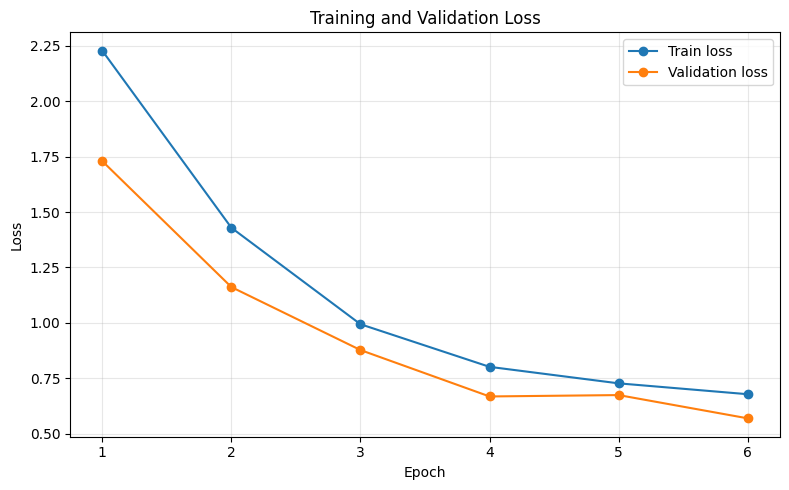

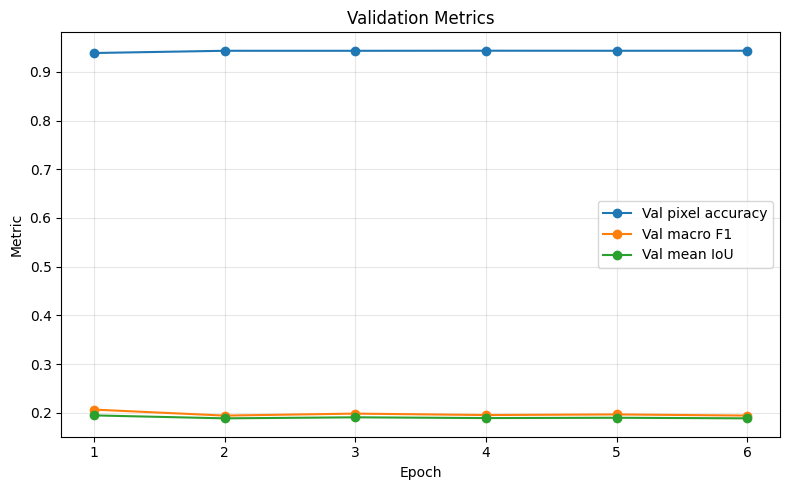

In [15]:
# ----------------------------
# Plot training history
# ----------------------------
if len(history) > 0:
    history_df = pd.DataFrame(history)

    plt.figure(figsize=(8, 5))
    plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train loss")
    plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "loss_curve.png", dpi=150)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(history_df["epoch"], history_df["val_pixel_accuracy"], marker="o", label="Val pixel accuracy")
    plt.plot(history_df["epoch"], history_df["val_macro_f1"], marker="o", label="Val macro F1")
    plt.plot(history_df["epoch"], history_df["val_mean_iou"], marker="o", label="Val mean IoU")
    plt.xlabel("Epoch")
    plt.ylabel("Metric")
    plt.title("Validation Metrics")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "validation_metrics_curve.png", dpi=150)
    plt.show()

In [16]:
# ----------------------------
# Load best checkpoint safely and evaluate on validation + test sets
# ----------------------------
best_model = SiamUnet().to(DEVICE)
best_model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))
best_model.eval()

val_summary, val_per_class_df, val_cm = evaluate_model(best_model, val_data_loader, criterion_seg, criterion_damage, DEVICE)
test_summary, test_per_class_df, test_cm = evaluate_model(best_model, test_data_loader, criterion_seg, criterion_damage, DEVICE)

val_summary_df = print_metrics_table("Validation metrics for best model", val_summary, val_per_class_df)
test_summary_df = print_metrics_table("Test metrics for best model", test_summary, test_per_class_df)

# Save quantitative result tables.
val_summary_df.to_csv(RESULTS_DIR / "validation_summary_metrics.csv", index=False)
val_per_class_df.to_csv(RESULTS_DIR / "validation_per_class_metrics.csv", index=False)
test_summary_df.to_csv(RESULTS_DIR / "test_summary_metrics.csv", index=False)
test_per_class_df.to_csv(RESULTS_DIR / "test_per_class_metrics.csv", index=False)

print("Saved metric CSV files to:", RESULTS_DIR)


Validation metrics for best model


,pixel_accuracy,macro_precision,macro_recall,macro_f1,mean_iou,mean_dice,loss
0,0.943306,0.31093,0.200682,0.195545,0.189357,0.195545,0.669055



Per-class metrics:


,class_id,class_name,support_pixels,precision,recall,f1,iou,dice
0,0,background,7417801,0.943380,0.999946,0.970839,0.943331,0.970839
1,1,no_damage,306945,0.611271,0.003463,0.006887,0.003456,0.006887
2,2,minor_damage,28857,0.000000,0.000000,0.000000,0.000000,0.000000
3,3,major_damage,88135,0.000000,0.000000,0.000000,0.000000,0.000000
4,4,destroyed,22582,0.000000,0.000000,0.000000,0.000000,0.000000



Test metrics for best model


,pixel_accuracy,macro_precision,macro_recall,macro_f1,mean_iou,mean_dice,loss
0,0.963861,0.215597,0.200033,0.196405,0.192815,0.196405,0.523961



Per-class metrics:


,class_id,class_name,support_pixels,precision,recall,f1,iou,dice
0,0,background,7580429,0.963906,0.999952,0.981598,0.963861,0.981598
1,1,no_damage,219638,0.114078,0.000214,0.000427,0.000214,0.000427
2,2,minor_damage,16909,0.000000,0.000000,0.000000,0.000000,0.000000
3,3,major_damage,35174,0.000000,0.000000,0.000000,0.000000,0.000000
4,4,destroyed,12170,0.000000,0.000000,0.000000,0.000000,0.000000


Saved metric CSV files to: C:\Users\Jana Ehab\Downloads\xbd\results


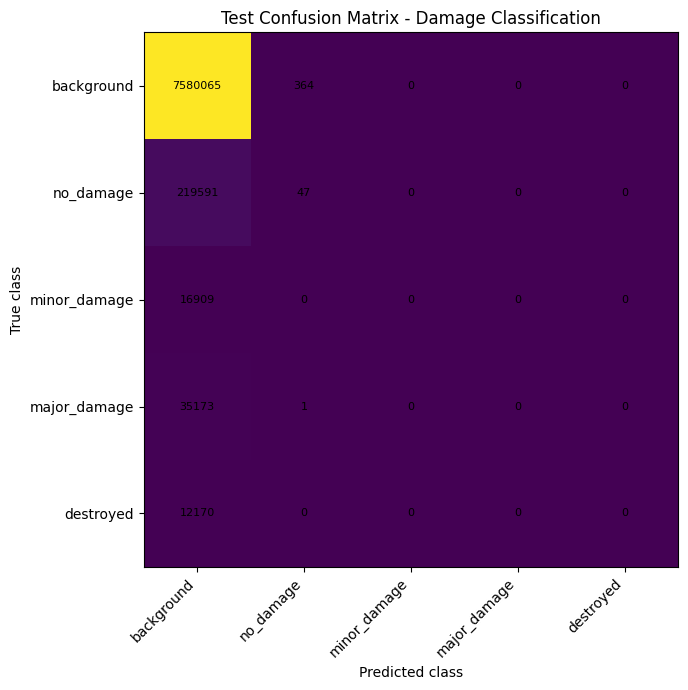

Saved confusion matrix to: C:\Users\Jana Ehab\Downloads\xbd\results\test_confusion_matrix.png


In [17]:
# ----------------------------
# Confusion matrix figure for the damage classes
# ----------------------------
cm_np = test_cm.numpy()

plt.figure(figsize=(8, 7))
plt.imshow(cm_np)
plt.title("Test Confusion Matrix - Damage Classification")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.xticks(range(NUM_DAMAGE_CLASSES), CLASS_NAMES, rotation=45, ha="right")
plt.yticks(range(NUM_DAMAGE_CLASSES), CLASS_NAMES)

for i in range(NUM_DAMAGE_CLASSES):
    for j in range(NUM_DAMAGE_CLASSES):
        plt.text(j, i, int(cm_np[i, j]), ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "test_confusion_matrix.png", dpi=150)
plt.show()
print("Saved confusion matrix to:", RESULTS_DIR / "test_confusion_matrix.png")

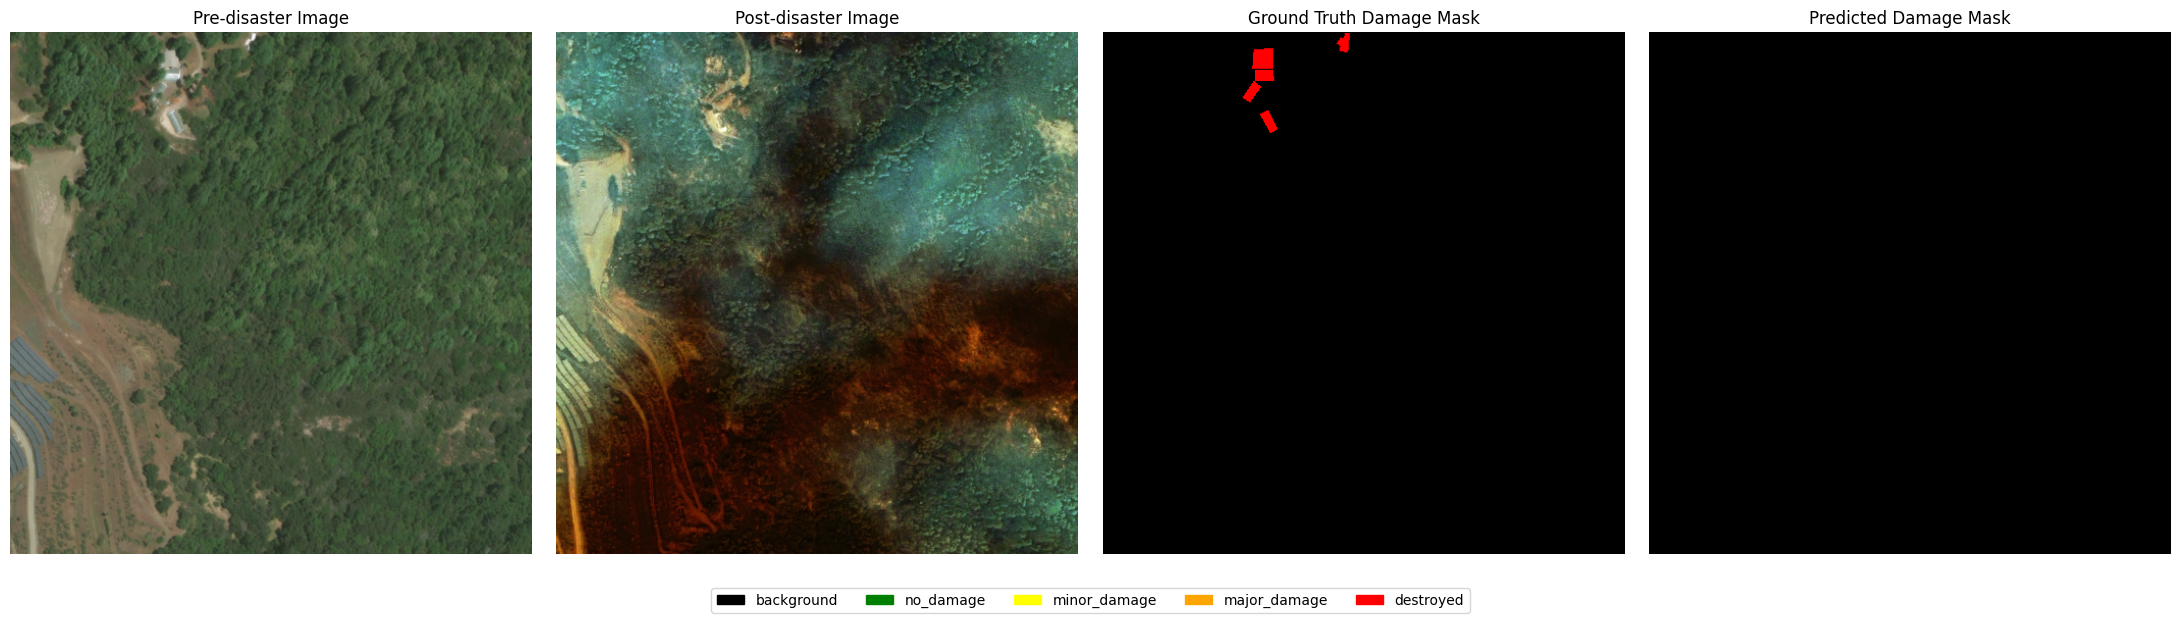

GT mask shape: (512, 512)
Pred mask shape: (512, 512)
Saved qualitative result figure to: C:\Users\Jana Ehab\Downloads\xbd\results\qualitative_prediction_example.png


In [18]:
# ----------------------------
# Qualitative result figure: pre image, post image, ground truth mask, prediction mask
# ----------------------------
from matplotlib.colors import ListedColormap

sample_idx = 0
batch = next(iter(test_data_loader))
test_pre_img, test_pre_mask, test_post_img, test_post_mask = batch

best_model.eval()
with torch.no_grad():
    outputs = best_model(test_pre_img.to(DEVICE), test_post_img.to(DEVICE))

damage_logits = outputs[2]
pred_mask = torch.argmax(damage_logits[sample_idx], dim=0).detach().cpu().numpy()
gt_mask = torch.argmax(test_post_mask[sample_idx], dim=0).detach().cpu().numpy()

pre_img = test_pre_img[sample_idx].detach().cpu().permute(1, 2, 0).numpy()
post_img = test_post_img[sample_idx].detach().cpu().permute(1, 2, 0).numpy()
pre_img = np.clip(pre_img, 0, 1)
post_img = np.clip(post_img, 0, 1)

# 0 background, 1 no damage, 2 minor, 3 major, 4 destroyed
mask_cmap = ListedColormap(["black", "green", "yellow", "orange", "red"])

fig, ax = plt.subplots(1, 4, figsize=(22, 6))
ax[0].imshow(pre_img)
ax[0].set_title("Pre-disaster Image")
ax[0].axis("off")

ax[1].imshow(post_img)
ax[1].set_title("Post-disaster Image")
ax[1].axis("off")

ax[2].imshow(gt_mask, cmap=mask_cmap, vmin=0, vmax=4)
ax[2].set_title("Ground Truth Damage Mask")
ax[2].axis("off")

im = ax[3].imshow(pred_mask, cmap=mask_cmap, vmin=0, vmax=4)
ax[3].set_title("Predicted Damage Mask")
ax[3].axis("off")

# Add a simple legend.
handles = [plt.Rectangle((0, 0), 1, 1, color=mask_cmap(i)) for i in range(NUM_DAMAGE_CLASSES)]
fig.legend(handles, CLASS_NAMES, loc="lower center", ncol=5)

plt.tight_layout(rect=[0, 0.08, 1, 1])
qual_path = RESULTS_DIR / "qualitative_prediction_example.png"
plt.savefig(qual_path, dpi=150)
plt.show()

print("GT mask shape:", gt_mask.shape)
print("Pred mask shape:", pred_mask.shape)
print("Saved qualitative result figure to:", qual_path)

In [19]:
# ----------------------------
# Final compact result table for the technical report
# ----------------------------
report_results = pd.DataFrame([
    {
        "Model": "Siamese U-Net",
        "Loss": LOSS_NAME,
        "Optimizer": OPTIMIZER_NAME,
        "Dataset": "xBD full train split, resized to 512x512",
        "Test Pixel Accuracy": test_summary["pixel_accuracy"],
        "Test Macro F1": test_summary["macro_f1"],
        "Test Mean IoU": test_summary["mean_iou"],
        "Test Mean Dice": test_summary["mean_dice"],
        "Test Loss": test_summary["loss"],
    }
])

display(report_results)
report_results.to_csv(RESULTS_DIR / "report_results_table.csv", index=False)
print("Saved final report table to:", RESULTS_DIR / "report_results_table.csv")

,Model,Loss,Optimizer,Dataset,Test Pixel Accuracy,Test Macro F1,Test Mean IoU,Test Mean Dice,Test Loss
0,Siamese U-Net,cross_entropy,adam,"xBD full train split, resized to 512x512",0.963861,0.196405,0.192815,0.196405,0.523961


Saved final report table to: C:\Users\Jana Ehab\Downloads\xbd\results\report_results_table.csv
